# MLT Assignment #1 - Decision Trees and Random Forests

This notebook predicts the binary `Activity` target from molecular descriptors in `bioresponse.csv`.

It completes all four requirements:

1. Train a small decision tree, a deep decision tree, a random forest with small trees, and a random forest with deep trees using a stratified 75% / 25% train-test split.
2. Report precision, recall, accuracy, F1-score, and log-loss on the held-out test set.
3. Plot precision-recall and ROC curves.
4. Build a cost-sensitive classifier that reduces Type II (false-negative) errors and achieves test recall above 0.95.

All random seeds are fixed for reproducibility. The test set is used only for final evaluation; the high-recall decision threshold is selected on a validation subset of the training data.

## 1. Imports and configuration

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.25

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

## 2. Load and inspect the data

In [6]:
data_path = Path("bioresponse.csv")
if not data_path.exists():
    raise FileNotFoundError(
        "Place bioresponse.csv in the same directory as this notebook before running it."
    )

bioresponse = pd.read_csv(data_path)

if "Activity" not in bioresponse.columns:
    raise ValueError("The dataset must contain an 'Activity' target column.")

X = bioresponse.drop(columns="Activity")
y = bioresponse["Activity"].astype(int)

dataset_summary = pd.Series(
    {
        "Rows": len(bioresponse),
        "Predictor columns": X.shape[1],
        "Missing values": int(bioresponse.isna().sum().sum()),
        "Positive class share": y.mean(),
    },
    name="Dataset summary",
)
display(dataset_summary.to_frame())
display(y.value_counts().sort_index().rename("count").to_frame())

,Dataset summary
Rows,3751.0000
Predictor columns,1776.0000
Missing values,0.0000
Positive class share,0.5423


,count
Activity,
0,1717
1,2034


## 3. Stratified 75% / 25% train-test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame(
    {
        "rows": [len(X_train), len(X_test)],
        "positive_share": [y_train.mean(), y_test.mean()],
    },
    index=["train", "test"],
)
display(split_summary)

,rows,positive_share
train,2813,0.5421
test,938,0.5426


## 4. Train the four required classifiers

The *small* models restrict each tree to depth 3. The *deep* models leave depth unrestricted. For the random forests, 200 trees provide stable estimates while keeping the notebook quick to run.

In [8]:
models = {
    "Small decision tree": DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=10,
        random_state=RANDOM_STATE,
    ),
    "Deep decision tree": DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
    ),
    "Random forest (small trees)": RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "Random forest (deep trees)": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}

for model in models.values():
    model.fit(X_train, y_train)

print(f"Trained {len(models)} classifiers.")

Trained 4 classifiers.


## 5. Test-set metrics

In [9]:
def evaluate_binary_classifier(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    return {
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "Accuracy": accuracy_score(y_true, prediction),
        "F1-score": f1_score(y_true, prediction, zero_division=0),
        "Log-loss": log_loss(y_true, probability),
    }


test_probabilities = {
    name: model.predict_proba(X_test)[:, 1]
    for name, model in models.items()
}

results = pd.DataFrame(
    {
        name: evaluate_binary_classifier(y_test, probability)
        for name, probability in test_probabilities.items()
    }
).T

display(results.round(4))

,Precision,Recall,Accuracy,F1-score,Log-loss
Small decision tree,0.7539,0.7525,0.7324,0.7532,0.7238
Deep decision tree,0.7169,0.7662,0.7090,0.7407,10.4903
Random forest (small trees),0.6953,0.7623,0.6898,0.7273,0.6057
Random forest (deep trees),0.7790,0.8173,0.7751,0.7977,0.4760


> Log-loss evaluates probability quality, not only the final class. An unrestricted single decision tree often outputs probabilities of exactly 0 or 1, so confident mistakes can produce a very large log-loss.

## 6. Precision-recall and ROC curves

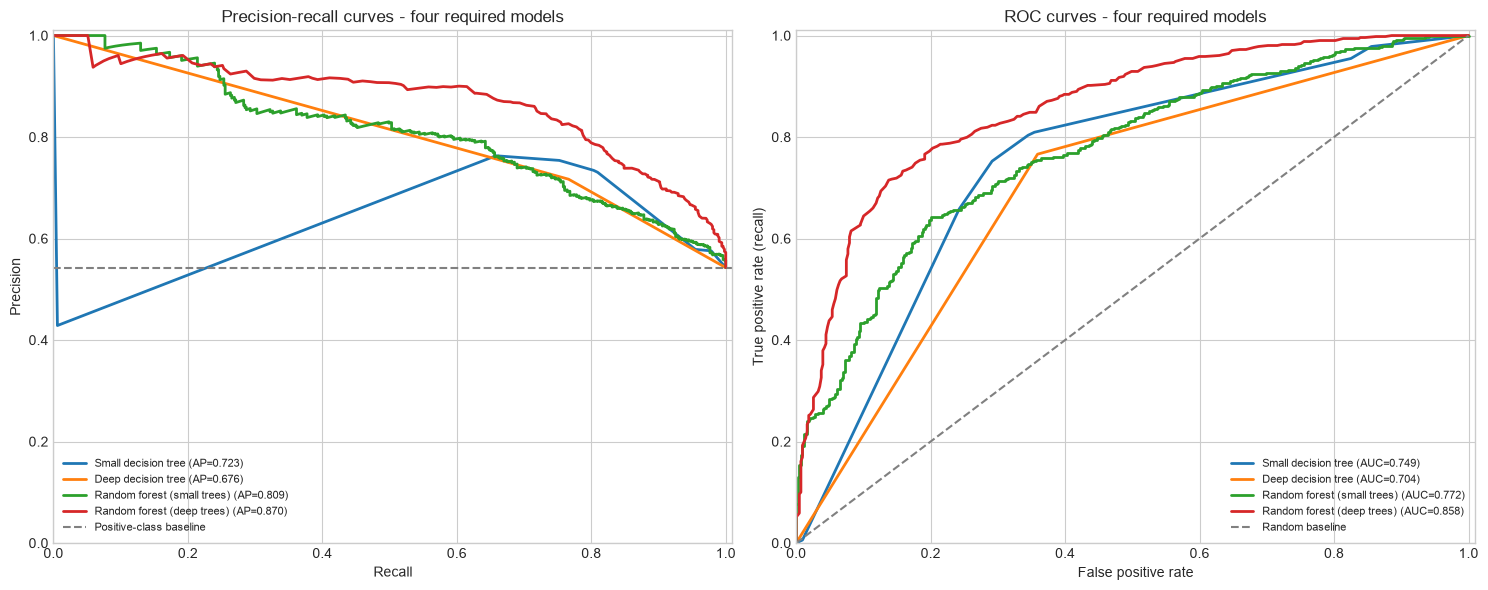

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name, probability in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probability)
    average_precision = average_precision_score(y_test, probability)
    axes[0].plot(recall, precision, linewidth=2, label=f"{name} (AP={average_precision:.3f})")

    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probability)
    auc = roc_auc_score(y_test, probability)
    axes[1].plot(false_positive_rate, true_positive_rate, linewidth=2, label=f"{name} (AUC={auc:.3f})")

axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label="Positive-class baseline")
axes[0].set(
    title="Precision-recall curves - four required models",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1.01),
    ylim=(0, 1.01),
)

axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random baseline")
axes[1].set(
    title="ROC curves - four required models",
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    xlim=(0, 1.01),
    ylim=(0, 1.01),
)

for axis in axes:
    axis.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.show()

## 7. Classifier designed to avoid Type II errors

False negatives are positive molecules incorrectly predicted as inactive. Two complementary choices reduce them:

- assign the positive class three times the weight of the negative class during training;
- lower the decision threshold from the default 0.50.

To avoid test-set leakage, the threshold is chosen on a validation subset taken only from the original training data. We require validation recall of at least 0.97 to leave a margin above the assignment's test-recall target of 0.95. After selecting the threshold, the model is refitted on the complete training set and evaluated once on the untouched test set.

In [11]:
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

safe_model_for_threshold = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    class_weight={0: 1, 1: 3},
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
safe_model_for_threshold.fit(X_fit, y_fit)

validation_probability = safe_model_for_threshold.predict_proba(X_validation)[:, 1]
candidate_thresholds = np.linspace(0.01, 0.99, 99)
validation_recall = np.array([
    recall_score(y_validation, validation_probability >= threshold)
    for threshold in candidate_thresholds
])

target_validation_recall = 0.97
eligible_thresholds = candidate_thresholds[validation_recall >= target_validation_recall]
if eligible_thresholds.size == 0:
    raise RuntimeError("No threshold achieved the requested validation recall.")

# The highest eligible threshold sacrifices the least precision while meeting the recall target.
safe_threshold = eligible_thresholds.max()
selected_validation_recall = recall_score(
    y_validation,
    validation_probability >= safe_threshold,
)

print(f"Selected threshold: {safe_threshold:.2f}")
print(f"Validation recall at selected threshold: {selected_validation_recall:.4f}")

Selected threshold: 0.39
Validation recall at selected threshold: 0.9712


In [12]:
safe_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    class_weight={0: 1, 1: 3},
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
safe_model.fit(X_train, y_train)

safe_probability = safe_model.predict_proba(X_test)[:, 1]
safe_prediction = (safe_probability >= safe_threshold).astype(int)
safe_results = pd.DataFrame(
    [evaluate_binary_classifier(y_test, safe_probability, threshold=safe_threshold)],
    index=["High-recall random forest"],
)

display(safe_results.round(4))

safe_test_recall = safe_results.loc["High-recall random forest", "Recall"]
assert safe_test_recall > 0.95, (
    f"Required recall > 0.95, but observed {safe_test_recall:.4f}."
)
print(f"Requirement satisfied: test recall = {safe_test_recall:.4f} > 0.95")

,Precision,Recall,Accuracy,F1-score,Log-loss
High-recall random forest,0.637,0.9686,0.6834,0.7685,0.5172


Requirement satisfied: test recall = 0.9686 > 0.95


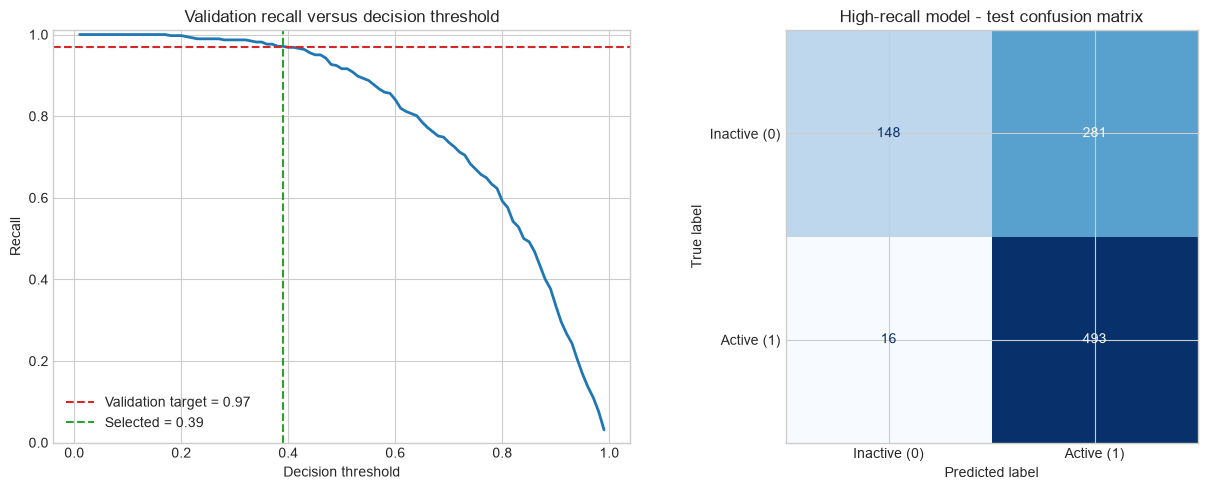

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(candidate_thresholds, validation_recall, linewidth=2)
axes[0].axhline(0.97, color="tab:red", linestyle="--", label="Validation target = 0.97")
axes[0].axvline(safe_threshold, color="tab:green", linestyle="--", label=f"Selected = {safe_threshold:.2f}")
axes[0].set(
    title="Validation recall versus decision threshold",
    xlabel="Decision threshold",
    ylabel="Recall",
    ylim=(0, 1.01),
)
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    safe_prediction,
    display_labels=["Inactive (0)", "Active (1)"],
    cmap="Blues",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("High-recall model - test confusion matrix")

plt.tight_layout()
plt.show()

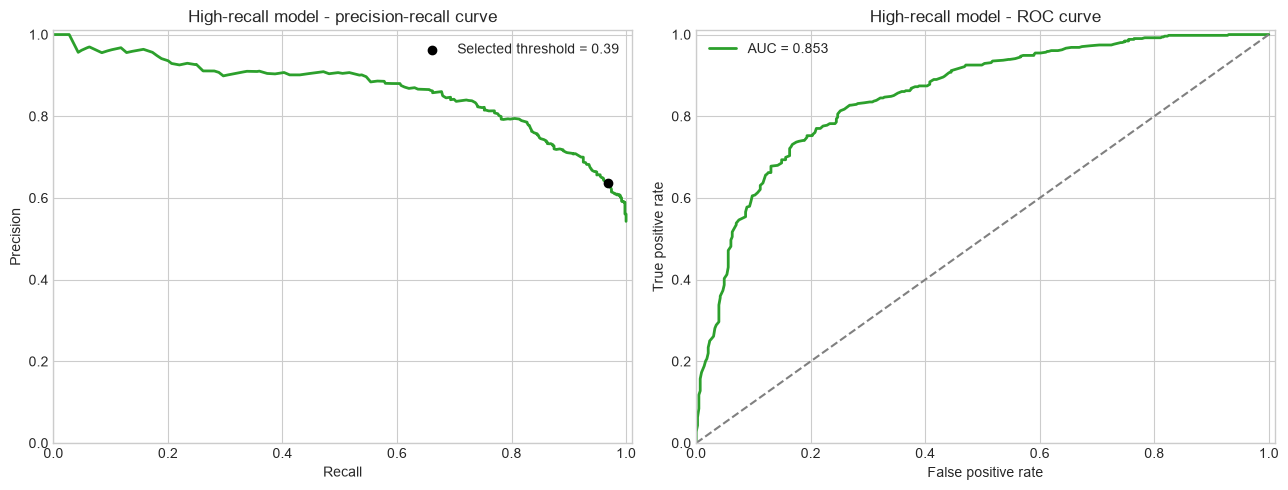

In [14]:
safe_precision, safe_recall_curve, _ = precision_recall_curve(y_test, safe_probability)
safe_fpr, safe_tpr, _ = roc_curve(y_test, safe_probability)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(safe_recall_curve, safe_precision, linewidth=2, color="tab:green")
axes[0].scatter(
    safe_results.loc["High-recall random forest", "Recall"],
    safe_results.loc["High-recall random forest", "Precision"],
    color="black",
    zorder=3,
    label=f"Selected threshold = {safe_threshold:.2f}",
)
axes[0].set(title="High-recall model - precision-recall curve", xlabel="Recall", ylabel="Precision", xlim=(0, 1.01), ylim=(0, 1.01))
axes[0].legend()

safe_auc = roc_auc_score(y_test, safe_probability)
axes[1].plot(safe_fpr, safe_tpr, linewidth=2, color="tab:green", label=f"AUC = {safe_auc:.3f}")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set(title="High-recall model - ROC curve", xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1.01), ylim=(0, 1.01))
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Conclusions

In [15]:
best_f1_model = results["F1-score"].idxmax()
best_log_loss_model = results["Log-loss"].idxmin()
false_negatives = int(confusion_matrix(y_test, safe_prediction)[1, 0])

display(Markdown(
    f"""- **Best F1-score among the four required models:** {best_f1_model} ({results.loc[best_f1_model, 'F1-score']:.4f}).
- **Best probability quality (lowest log-loss):** {best_log_loss_model} ({results.loc[best_log_loss_model, 'Log-loss']:.4f}).
- **High-recall classifier:** recall {safe_test_recall:.4f}, with {false_negatives} false negatives on {len(y_test)} test observations.
- The high-recall operating point deliberately trades precision and overall accuracy for fewer Type II errors. This is appropriate only when missing an active molecule is more costly than investigating extra false positives."""
))

- **Best F1-score among the four required models:** Random forest (deep trees) (0.7977).
- **Best probability quality (lowest log-loss):** Random forest (deep trees) (0.4760).
- **High-recall classifier:** recall 0.9686, with 16 false negatives on 938 test observations.
- The high-recall operating point deliberately trades precision and overall accuracy for fewer Type II errors. This is appropriate only when missing an active molecule is more costly than investigating extra false positives.